## Setup: seed & reproducibility

Seluruh keacakan dikunci agar hasil bisa diulang:
- `torch.manual_seed(67)` → inisialisasi bobot & sampling tensor PyTorch deterministik,
- `np.random.seed(67)` → shuffle / split NumPy deterministik.

Tanpa seed, tiap Run menghasilkan bobot awal $W_0$ berbeda sehingga kurva loss tidak bisa dibandingkan antar optimizer.

In [18]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)



## 1. Membaca dataset

Dataset $D$ berukuran $n=32833$ baris $\times$ $27$ kolom. Setiap baris = satu lagu dengan 12 fitur audio numerik dan satu label $y \in \{\text{10 kelas kesehatan mental}\}$.

> `low_memory=False` dipakai agar pandas menebak tipe kolom dalam sekali baca (menghilangkan `DtypeWarning` pada kolom campuran seperti `raga_name`).

In [19]:
df = pd.read_csv('Music_recommendation_withProperRagas.csv', low_memory=False)
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,Mental_Health_Label,raga_name,raga_label,instrument
0,697MjF1454XKvZmTuqkWmD,I Miss You,Jeriqo,45,2vJ6FDg6ZMS56U8Wbiw2Oz,I Miss You,2019-02-05,Pop Hits 2000-2019,6mtYuOxzl58vSGnEDtZ9uB,edm,...,0.004910,0.000013,0.0816,0.415,174.026,216347,Normal/Unclassified,NaN,Bageshree,Unknown
1,3x2bXiU0o4WbsPkawXlfDA,Who Are You,The Who,17,6LRJF97hgXHj8uMLHyCDbh,Who Are You (Remastered),1978-08-18,House Of The Rising Sun,1bMYfBHYBCRHY5LGkjlpSy,rock,...,0.265000,0.003130,0.1060,0.489,156.371,378707,Normal/Unclassified,NaN,Yaman,Guitar/Drums
2,0jEaPBjFAWjQTMVouRwaHi,Happy,The Beef Seeds,30,4IQn9XpweytNX2cUe2NBUH,Keepin' it Beefy,2015-01-19,Bluegrass Covers,37i9dQZF1DX56crgoe4TG3,r&b,...,0.665000,0.000000,0.1270,0.932,86.529,218044,Bipolar (Mania),NaN,Kafi,Unknown
3,5EKUb1FKsyYVaSXb41YBIj,ONE,Rev Theory,35,0gGic19XvEiHKKWBV7M4YM,ONE,2020-01-15,Rock Hard,37i9dQZF1DWWJOmJ7nRx0C,rock,...,0.000006,0.000000,0.3030,0.520,90.016,208196,Normal/Unclassified,NaN,Bageshree,Guitar/Drums
4,300DUx4tdtCdGEUXR032jA,Palace/Curse,The Internet,62,69g3CtOVg98TPOwqmI2K7Q,Ego Death,2015-06-26,NEO-soul,3q3M4VCymcMoxJ3Tl7mRqN,r&b,...,0.035100,0.000727,0.2430,0.261,67.104,440013,Normal/Unclassified,NaN,Kafi,Unknown


## 2. Intip 5 baris pertama

Verifikasi cepat: nama kolom, skala tiap fitur (mis. `tempo` ratusan vs `danceability` $0$–$1$), dan isi label `Mental_Health_Label`.

In [20]:
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,Mental_Health_Label,raga_name,raga_label,instrument
0,697MjF1454XKvZmTuqkWmD,I Miss You,Jeriqo,45,2vJ6FDg6ZMS56U8Wbiw2Oz,I Miss You,2019-02-05,Pop Hits 2000-2019,6mtYuOxzl58vSGnEDtZ9uB,edm,...,0.004910,0.000013,0.0816,0.415,174.026,216347,Normal/Unclassified,NaN,Bageshree,Unknown
1,3x2bXiU0o4WbsPkawXlfDA,Who Are You,The Who,17,6LRJF97hgXHj8uMLHyCDbh,Who Are You (Remastered),1978-08-18,House Of The Rising Sun,1bMYfBHYBCRHY5LGkjlpSy,rock,...,0.265000,0.003130,0.1060,0.489,156.371,378707,Normal/Unclassified,NaN,Yaman,Guitar/Drums
2,0jEaPBjFAWjQTMVouRwaHi,Happy,The Beef Seeds,30,4IQn9XpweytNX2cUe2NBUH,Keepin' it Beefy,2015-01-19,Bluegrass Covers,37i9dQZF1DX56crgoe4TG3,r&b,...,0.665000,0.000000,0.1270,0.932,86.529,218044,Bipolar (Mania),NaN,Kafi,Unknown
3,5EKUb1FKsyYVaSXb41YBIj,ONE,Rev Theory,35,0gGic19XvEiHKKWBV7M4YM,ONE,2020-01-15,Rock Hard,37i9dQZF1DWWJOmJ7nRx0C,rock,...,0.000006,0.000000,0.3030,0.520,90.016,208196,Normal/Unclassified,NaN,Bageshree,Guitar/Drums
4,300DUx4tdtCdGEUXR032jA,Palace/Curse,The Internet,62,69g3CtOVg98TPOwqmI2K7Q,Ego Death,2015-06-26,NEO-soul,3q3M4VCymcMoxJ3Tl7mRqN,r&b,...,0.035100,0.000727,0.2430,0.261,67.104,440013,Normal/Unclassified,NaN,Kafi,Unknown


## 3. Struktur & tipe data (`info`)

Total 27 kolom: 9 `float64` + 4 `int64` + 14 `str`. Yang dipakai model hanya 12 fitur numerik + 1 kolom label; sisanya (id lagu, nama playlist, raga, instrumen, …) adalah metadata.

In [21]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

## 4. Data hilang (`isna`)

Menghitung $\sum_i \mathbf{1}[x_i = \text{NaN}]$ per kolom. Kolom audio & label lengkap ($0$ hilang); yang kosong hanya metadata (`raga_name` 32827 kosong) sehingga tidak mengganggu training.

In [22]:
df.isna().sum()[df.isna().sum() > 0]

track_name              5
track_artist            5
track_album_name        5
raga_name           32827
dtype: int64

## 5. Definisi fitur $X$ dan label $y$

$$X \in \mathbb{R}^{n \times 12}, \qquad y \in \{0,\dots,9\}^n$$

12 fitur audio (skala beda jauh — alasan perlunya standardisasi di §8). `target` ditulis sebagai **string** (bukan list) agar `y` berupa Series 1-D dan tidak memicu `DataConversionWarning` di `LabelEncoder`.

In [23]:
features = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms'
]

target = 'Mental_Health_Label'  # plain string -> 1-D Series (avoids DataConversionWarning)


## 6. Matriks $X$ dan vektor $y$

`X = df[features]` mengambil blok numerik $n \times 12$, `y = df[target]` mengambil vektor label $n \times 1$. Keduanya masih berupa DataFrame/Series pandas — konversi ke tensor dilakukan di `load_data` (§8).

In [24]:
X = df[features]
y = df[target]

Disimpan ke: distribusi_label.png


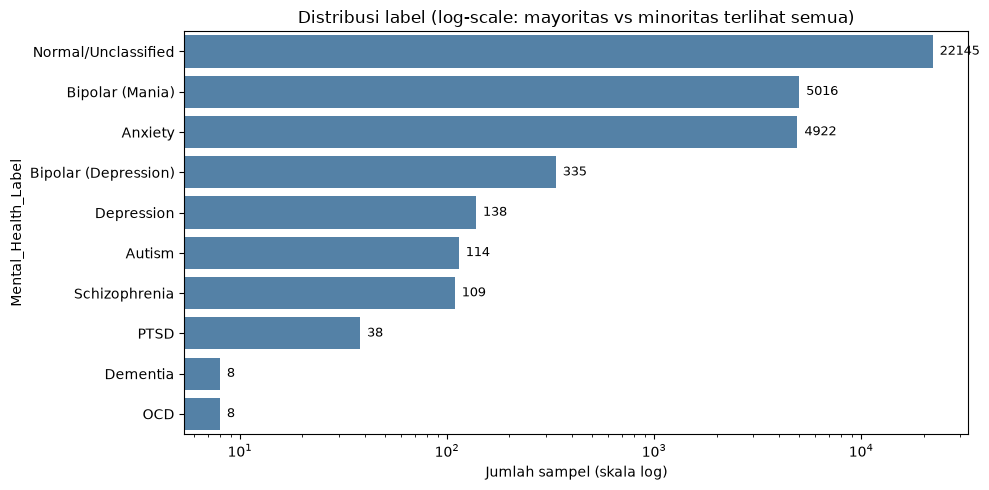

Disimpan ke: distribusi_fitur.png


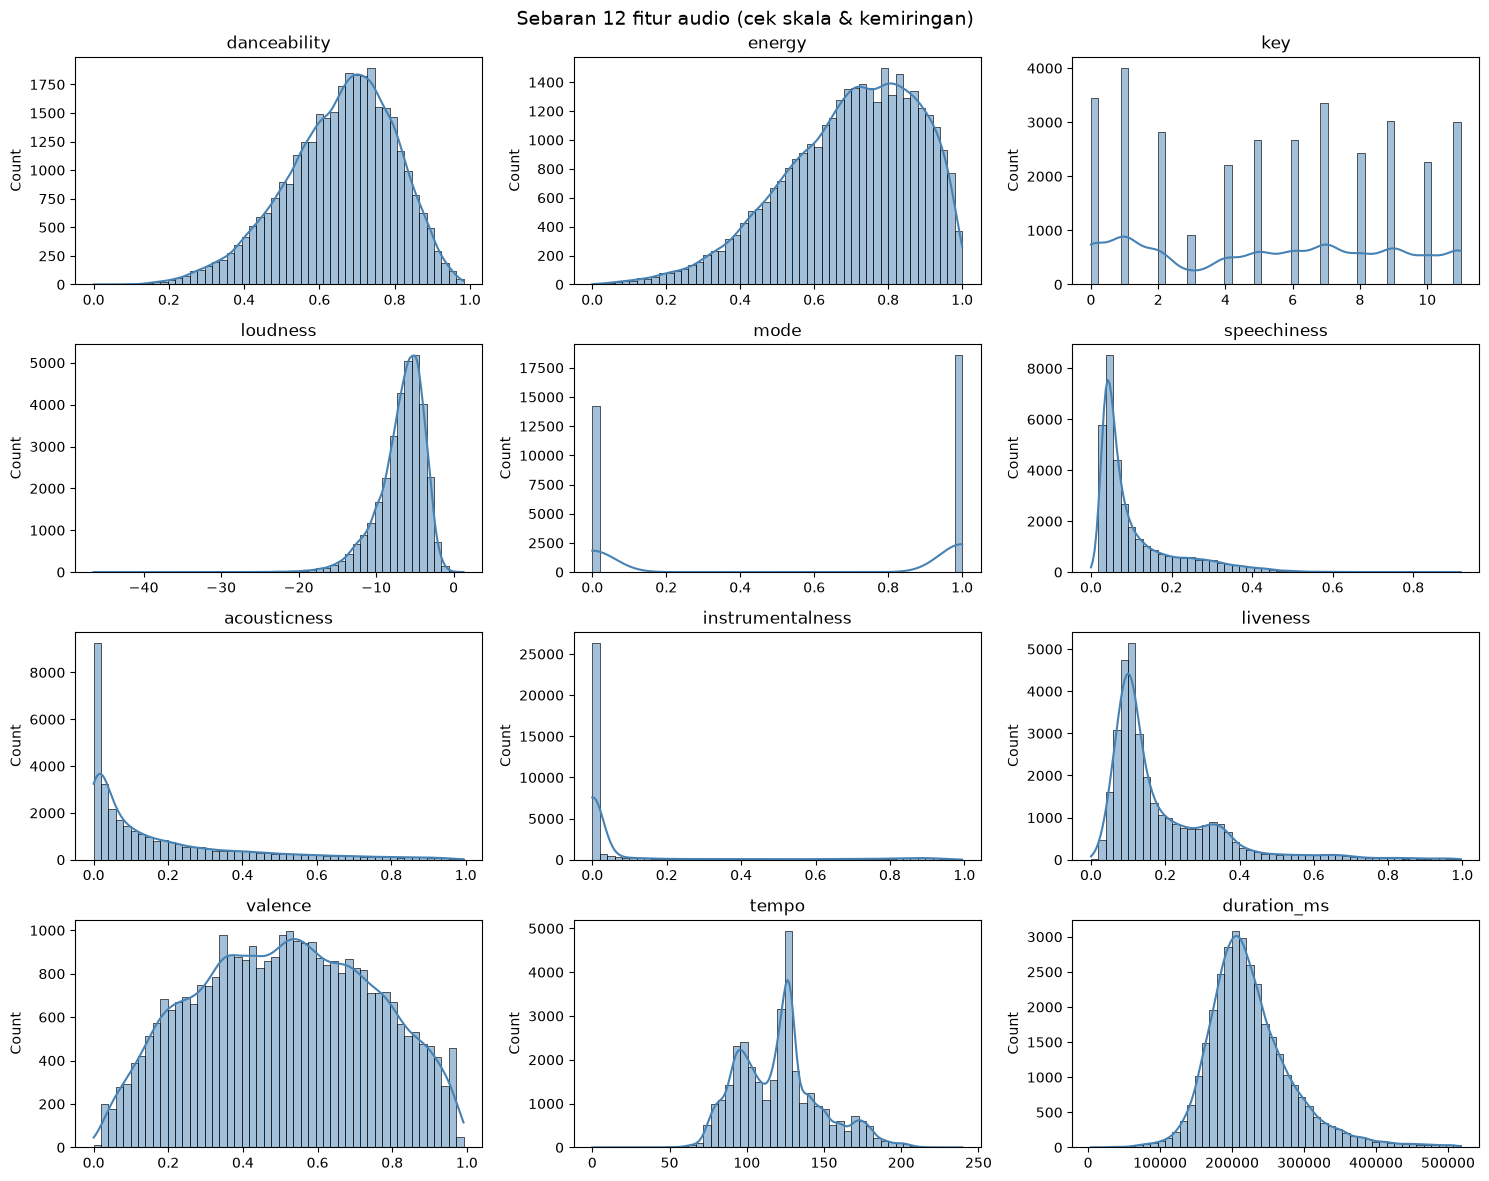

In [39]:
counts = y.value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=counts.values, y=counts.index, orient="h", color="steelblue")
plt.xscale("log")
for i, v in enumerate(counts.values):
    plt.text(v * 1.08, i, str(v), va="center", fontsize=9)
plt.xlabel("Jumlah sampel (skala log)")
plt.ylabel("Mental_Health_Label")
plt.title("Distribusi label (log-scale: mayoritas vs minoritas terlihat semua)")
plt.tight_layout()
plt.savefig("distribusi_label.png")
print("Disimpan ke: distribusi_label.png")
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, features):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Sebaran 12 fitur audio (cek skala & kemiringan)", fontsize=14)
plt.tight_layout()
plt.savefig("distribusi_fitur.png")
print("Disimpan ke: distribusi_fitur.png")
plt.show()

## 7. Sebaran label: data timpang!

$$\text{mayoritas} = \frac{22145}{32833} \approx 0{,}674$$

Menebak `"Normal/Unclassified"` terus-menerus saja sudah berakurasi $\approx 67\%$, sementara kelas minoritas (`OCD`, `Dementia` masing-masing $8$ sampel) nyaris tak terwakili. Inilah alasan akurasi biasa **menipu** dan kita butuh *balanced accuracy* + *macro-F1* (§12). `stratify` pada split (§8) menjaga proporsi ini di tiap subset.

In [25]:
y.value_counts()

Mental_Health_Label
Normal/Unclassified     22145
Bipolar (Mania)          5016
Anxiety                  4922
Bipolar (Depression)      335
Depression                138
Autism                    114
Schizophrenia             109
PTSD                       38
Dementia                    8
OCD                         8
Name: count, dtype: int64

## 8. Korelasi antar fitur (Pearson)

$$r_{jk} = \frac{\sum_i (x_{ij}-\bar{x}_j)(x_{ik}-\bar{x}_k)}
{\sqrt{\sum_i (x_{ij}-\bar{x}_j)^2}\sqrt{\sum_i (x_{ik}-\bar{x}_k)^2}} \in [-1, 1]$$

$|r| \approx 1$ berarti dua fitur membawa informasi yang sama (redundan); $|r| \approx 0$ berarti independen. Heatmap dipakai untuk memastikan tidak ada fitur yang identik/duplikat sebelum training.

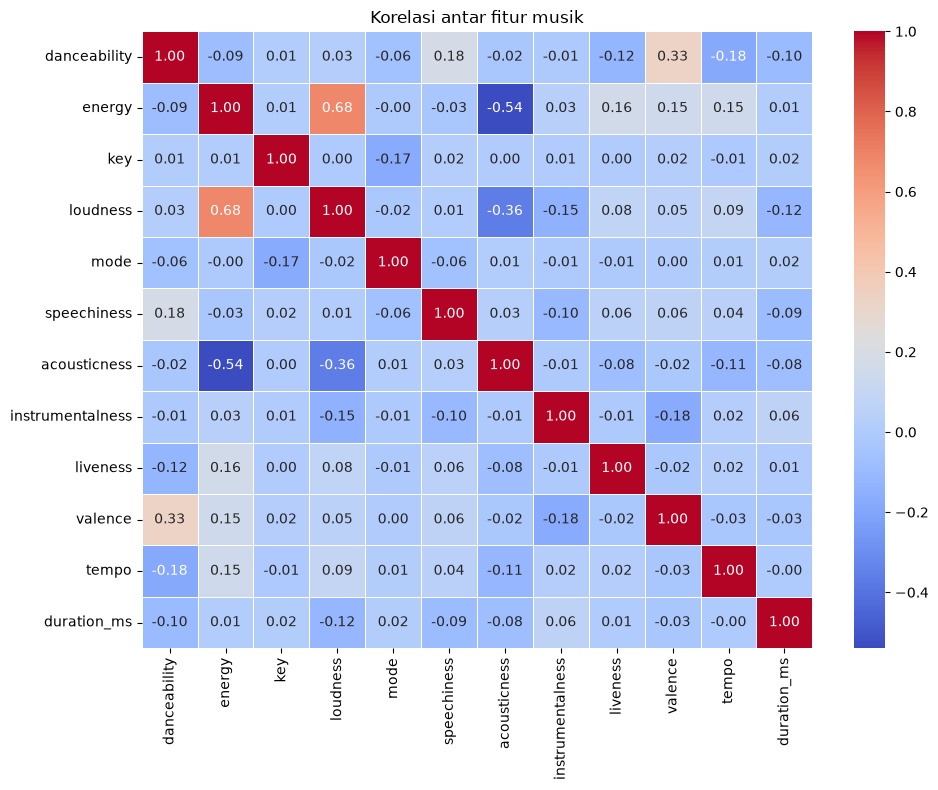

In [26]:
correlation_matrix = X.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Korelasi antar fitur musik")
plt.tight_layout()
plt.show()

## 9. `load_data`: encode → split 70/15/15 → standarisasi → tensor

1. **Encode.** Label teks $y^{\text{teks}}$ dipetakan ke $y \in \{0,\dots,9\}$ via `LabelEncoder`.
2. **Split bertingkat + stratify** (proporsi kelas dipertahankan):
   $$n_{\text{latih}} = 22983,\quad n_{\text{val}} = 4925,\quad n_{\text{uji}} = 4925$$
   Aturan pakai: *tuning* ($lr$, `sizes`, aktivasi) hanya melihat **validasi**; **uji** dibuka sekali di akhir.
3. **Standarisasi** ($z$-score) per fitur $j$, dengan $\mu_j, \sigma_j$ dihitung **hanya dari data latih**:
   $$\tilde{x}_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad \mu_j = 0,\ \sigma_j = 1\ \text{setelah transformasi}$$
   Tanpa ini, fitur berskala besar (`duration_ms` $\sim 10^5$) mendominasi gradien dan training tidak stabil.
4. **Tensor.** $X$ → `float32`, $y$ → `long` (syarat `cross_entropy`).

In [27]:
# -------------------------------------------------------------
#  5. PREPARE TRAIN / VAL / TEST DATA
# -------------------------------------------------------------
# Steps:
#   a. Encode text labels -> integers (LabelEncoder)
#   b. Stratified 70% train / 15% val / 15% test split (keeps class proportions)
#      - validation: for selecting lr/sizes/activation
#      - test: opened once at the end for the final report
#   c. Standardize features (mean=0, std=1) for stable training
#      - tempo & duration_ms are large-scale; training struggles without scaling
#      - the scaler is fit on TRAIN data only (val/test are just transformed)
#   d. Convert to float32 / long tensors
_label_encoder: LabelEncoder | None = None  # reused for class names in report()


def load_data(test_size=0.15, val_size=0.15, random_state=SEED):
    """Reload the CSV -> return 6 tensors: (Xtr, ytr, Xval, yval, Xte, yte)."""
    global _label_encoder

    data = pd.read_csv('Music_recommendation_withProperRagas.csv', low_memory=False)
    X_raw = data[features].to_numpy(dtype=np.float32)
    y_raw = data[target].to_numpy()

    # a. Encode text labels -> integers 0..9
    _label_encoder = LabelEncoder()
    y_encoded = _label_encoder.fit_transform(y_raw)
    print("Daftar kelas:", list(_label_encoder.classes_))

    # b1. Split off the test set first (15% of total)
    X_rest, X_te, y_rest, y_te = train_test_split(
        X_raw, y_encoded, test_size=test_size,
        random_state=random_state, stratify=y_encoded,
    )
    # b2. Split validation from the remainder (15% of total)
    val_rel = val_size / (1 - test_size)  # validation share relative to the remainder
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_rest, y_rest, test_size=val_rel,
        random_state=random_state, stratify=y_rest,
    )
    print(f"Bagi data -> latih {len(X_tr)}, validasi {len(X_val)}, uji {len(X_te)}")

    # c. Scaling (fit on train only!)
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_te = scaler.transform(X_te).astype(np.float32)

    # d. To PyTorch tensors
    return (
        torch.from_numpy(X_tr), torch.from_numpy(y_tr).long(),
        torch.from_numpy(X_val), torch.from_numpy(y_val).long(),
        torch.from_numpy(X_te), torch.from_numpy(y_te).long(),
    )

## 10. Inisialisasi bobot `init_layer`

Untuk layer $W \in \mathbb{R}^{f_{\text{out}} \times f_{\text{in}}}$ dengan bias $b = 0$:
- **He** (untuk ReLU): $W_{ij} \sim \mathcal{N}\!\left(0,\, \frac{2}{f_{\text{in}}}\right)$ — menjaga $\mathrm{Var}(h^{(l)}) \approx \mathrm{Var}(h^{(l-1)})$ karena ReLU mematikan separuh aktivasi;
- **Xavier** (untuk tanh/sigmoid): $W_{ij} \sim \mathcal{N}\!\left(0,\, \frac{2}{f_{\text{in}}+f_{\text{out}}}\right)$ — menjaga variansi maju **dan** gradien mundur;
- `small/large/const/zero`: varian kecil ($0{,}01$), besar ($1$), konstan ($0{,}1$), nol — untuk eksperimen divergensi.

`"default"` membiarkan inisialisasi bawaan PyTorch $U(-1/\sqrt{f_{\text{in}}},\, 1/\sqrt{f_{\text{in}}})$.

In [28]:
def init_layer(layer: nn.Linear, init: str = "he"):
    """Re-initialize one nn.Linear in place.

    Options for `init`:
      default = keep PyTorch's default init, small = N(0, 0.01),
      const = 0.1, zero = 0, large = N(0, 1.0),
      xavier / he = Gaussian scaled by layer size.
    Bias is always zeroed (except in "default" mode).
    """
    W, b = layer.weight, layer.bias
    fan_out, fan_in = W.shape  # PyTorch stores weights as [out, in]

    with torch.no_grad():
        if init == "default":
            return
        elif init == "zero":
            W.zero_()
        elif init == "const":
            W.fill_(0.1)
        elif init == "small":
            W.normal_(0, 0.01)
        elif init == "large":
            W.normal_(0, 1.0)
        elif init == "xavier":
            W.normal_(0, math.sqrt(2.0 / (fan_in + fan_out)))
        elif init == "he":
            W.normal_(0, math.sqrt(2.0 / fan_in))
        else:
            raise ValueError(f"Unknown init: {init}")
        b.zero_()

## 11. Model MLP: forward, loss, dan aktivasi dinamis

**Forward.** Untuk `sizes` $=(d_0, d_1, \dots, d_L)$, tiap hidden layer:
$$z^{(l)} = W^{(l)} h^{(l-1)} + b^{(l)}, \qquad h^{(l)} = \sigma(z^{(l)}),\quad l = 1,\dots,L-1$$
dengan $h^{(0)} = x$ dan $\sigma \in \{\mathrm{ReLU}, \tanh, \mathrm{sigmoid}, \dots\}$ dipilih via `activation`. Contoh `sizes=(12,64,32,10)`:
$$12 \xrightarrow{\ \sigma\ } 64 \xrightarrow{\ \sigma\ } 32 \longrightarrow 10\ \text{logits}$$

**Kenapa layer terakhir tanpa aktivasi?** Loss-nya cross-entropy dengan softmax di dalamnya:
$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log \frac{e^{z_{i,y_i}}}{\sum_{k=1}^{10} e^{z_{i,k}}}$$
Memberi softmax/sigmoid/ReLU sebelumnya = aktivasi ganda (gradien rusak). Prediksi cukup $\hat{y}_i = \arg\max_k z_{i,k}$ karena $\arg\max$ invarian terhadap softmax.

In [29]:
def _get_activation(name):
    options = {
        "relu": F.relu,
        "tanh": torch.tanh,
        "sigmoid": torch.sigmoid,
        "leaky_relu": F.leaky_relu,
        "gelu": F.gelu,
        "elu": F.elu,
    }
    if callable(name):  # a custom function (e.g. F.silu) is also accepted
        return name
    try:
        return options[name]
    except KeyError:
        raise ValueError(f"Unknown activation: {name}. Choose from: {sorted(options)}")


class MLP(nn.Module):
    def __init__(self, sizes=(12, 64, 32, 10), init="he", seed=SEED, activation="relu"):
        super().__init__()
        torch.manual_seed(seed)  # for reproducibility
        self.act = _get_activation(activation)
        self.activation_name = activation if isinstance(activation, str) else "custom"
        self.layers = nn.ModuleList(
            nn.Linear(n_in, n_out) for n_in, n_out in zip(sizes[:-1], sizes[1:])
        )
        for layer in self.layers:
            init_layer(layer, init)
        # Flat parameter list for the manual optimizers below
        self.params = [p for layer in self.layers for p in (layer.weight, layer.bias)]

    def forward(self, x):
        """Return (logits, per-layer activations). No activation on the last layer."""
        acts = [x]
        h = x
        for i, layer in enumerate(self.layers):
            z = layer(h)
            h = z if i == len(self.layers) - 1 else self.act(z)
            acts.append(h)
        return h, acts

    def _compute_loss(self, logits, y):
        return F.cross_entropy(logits, y)  # mean cross-entropy

    def loss_and_grads(self, x, y):
        """Compute the loss and its gradients (used at every training step)."""
        logits, _ = self.forward(x)
        loss = self._compute_loss(logits, y)
        grads = torch.autograd.grad(loss, self.params)
        return loss.item(), list(grads)

    @torch.no_grad()
    def loss(self, x, y):
        logits, _ = self.forward(x)
        return self._compute_loss(logits, y).item()

    @torch.no_grad()
    def accuracy(self, x, y):
        logits, _ = self.forward(x)
        preds = logits.argmax(dim=1)
        return (preds == y).float().mean().item()

## 12. Optimizer manual (tanpa `torch.optim`, untuk belajar)

Semua mengembalikan `step(params, grads)` dengan gradien $g_t = \nabla_w \mathcal{L}_{\text{batch}}$:
- **SGD:** $w \leftarrow w - \eta\, g_t$
- **Momentum:** $v \leftarrow \beta v + g_t,\quad w \leftarrow w - \eta\, v$ — meredam osilasi ($\beta = 0{,}9$);
- **RMSprop:** $s \leftarrow \rho s + (1-\rho)\, g_t^2,\quad w \leftarrow w - \eta\, g_t / (\sqrt{s} + \epsilon)$ — *learning rate* adaptif per bobot;
- **Adam** = keduanya + koreksi bias: $m_t, v_t$ dibagi $(1-\beta_1^t)$, $(1-\beta_2^t)$ agar tak bias ke $0$ di step awal.

In [30]:
def make_sgd(lr=0.1):
    """Plain SGD: w -= lr * gradient."""
    def step(params, grads):
        with torch.no_grad():
            for p, g in zip(params, grads):
                p -= lr * g
    return step


def make_momentum(lr=0.01, beta=0.9):
    """SGD + momentum: reuse the previous direction to reduce oscillation."""
    velocity = {}

    def step(params, grads):
        with torch.no_grad():
            for i, (p, g) in enumerate(zip(params, grads)):
                velocity[i] = beta * velocity.get(i, 0) + g
                p -= lr * velocity[i]
    return step


def make_rmsprop(lr=0.001, rho=0.99, eps=1e-8):
    """RMSprop: a per-weight adaptive learning rate."""
    sq_avg = {}

    def step(params, grads):
        with torch.no_grad():
            for i, (p, g) in enumerate(zip(params, grads)):
                sq_avg[i] = rho * sq_avg.get(i, 0) + (1 - rho) * g * g
                p -= lr * g / (torch.sqrt(sq_avg[i]) + eps)
    return step


def make_adam(lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8, bias_correction=True):
    """Adam = momentum + RMSprop + bias correction for the early steps."""
    m, v = {}, {}
    step_count = 0

    def step(params, grads):
        nonlocal step_count
        step_count += 1
        with torch.no_grad():
            for i, (p, g) in enumerate(zip(params, grads)):
                m[i] = beta1 * m.get(i, 0) + (1 - beta1) * g
                v[i] = beta2 * v.get(i, 0) + (1 - beta2) * g * g
                if bias_correction:
                    m_hat = m[i] / (1 - beta1 ** step_count)
                    v_hat = v[i] / (1 - beta2 ** step_count)
                else:
                    m_hat, v_hat = m[i], v[i]
                p -= lr * m_hat / (torch.sqrt(v_hat) + eps)
    return step

## 13. `train` & `evaluate`: minibatch dan deteksi divergensi

Tiap step: ambil minibatch $B=64$ (reshuffle tiap epoch) → `loss_and_grads` → `step(params, grads)`. `train` mengembalikan `(loss_latih, akurasi_val, akurasi_uji, riwayat)` dengan riwayat = **loss validasi** tiap step (untuk memilih model). Run dengan loss/bobot non-finit ($\mathrm{NaN}/\infty$) ditandai divergen (`loss = inf`).

`evaluate` mengulang `trials` seed berbeda dan merata-ratakan — karena satu seed bisa beruntung/sial (terutama dengan kelas $8$ sampel).

In [31]:
def train(opt_factory, steps=300, batch_size=64, sizes=(12, 64, 32, 10),
          init="he", activation="relu", seed=0, data=None, track=False,
          return_model=False):
    """Train one model; return (train loss, val accuracy, test accuracy, history).

    - Minibatches are reshuffled each epoch, drawn from TRAIN data only.
    - track=True records VALIDATION loss each step (for model selection);
      history[0] = before training. Test data stays untouched during tuning.
    - A run with NaN/inf loss or weights is marked diverged (loss = inf).
    - return_model=True appends the trained model as the last element,
      for analysis (F1, confusion matrix) without retraining.
    """
    Xtr, ytr, Xval, yval, Xte, yte = data if data is not None else load_data()
    # Auto-fix the input/output dims if they mismatch the data
    sizes = list(sizes)
    sizes[0], sizes[-1] = Xtr.shape[1], int(ytr.max().item()) + 1
    model = MLP(tuple(sizes), init, seed, activation)
    step = opt_factory()

    rng = np.random.default_rng(1000 + seed)
    history = [model.loss(Xval, yval)] if track else []
    order, pos = rng.permutation(len(Xtr)), 0

    for _ in range(steps):
        if pos + batch_size > len(Xtr):  # epoch exhausted -> reshuffle
            order, pos = rng.permutation(len(Xtr)), 0
        idx = torch.as_tensor(order[pos:pos + batch_size])
        pos += batch_size

        batch_loss, grads = model.loss_and_grads(Xtr[idx], ytr[idx])
        step(model.params, grads)

        if not math.isfinite(batch_loss) or not all(torch.isfinite(p).all() for p in model.params):
            failed = (math.inf, float("nan"), float("nan"), history + [math.inf])
            return (*failed, model) if return_model else failed
        if track:
            history.append(model.loss(Xval, yval))

    final_loss = model.loss(Xtr, ytr)
    if not math.isfinite(final_loss):
        failed = (math.inf, float("nan"), float("nan"), history + [math.inf])
        return (*failed, model) if return_model else failed
    result = (final_loss, model.accuracy(Xval, yval), model.accuracy(Xte, yte), history)
    return (*result, model) if return_model else result


def evaluate(opt_factory, trials=5, **kwargs):
    """Repeat training over several seeds; return (loss, val accuracy, test accuracy, diverged count)."""
    data = load_data()
    losses, val_accs, test_accs, diverged = [], [], [], 0
    for t in range(trials):
        loss, av, at, _ = train(opt_factory, seed=t, data=data, **kwargs)
        if math.isfinite(loss):
            losses.append(loss)
            val_accs.append(av)
            test_accs.append(at)
        else:
            diverged += 1
    if not losses:
        return math.inf, float("nan"), float("nan"), diverged
    return float(np.mean(losses)), float(np.mean(val_accs)), float(np.mean(test_accs)), diverged


def train_epochs(opt_factory, epochs=20, batch_size=64, sizes=(12, 64, 32, 10),
                 init="he", activation="relu", seed=SEED, data=None,
                 return_model=False):
    """Latih per-epoch; return (train_loss, val_loss, train_acc, val_acc, test_acc, curves[, model]).

    curves = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[]) per epoch.
    1 epoch = satu pass penuh atas data latih (reshuffle tiap epoch).
    """
    Xtr, ytr, Xval, yval, Xte, yte = data if data is not None else load_data()
    sizes = list(sizes)
    sizes[0], sizes[-1] = Xtr.shape[1], int(ytr.max().item()) + 1
    model = MLP(tuple(sizes), init, seed, activation)
    step_fn = opt_factory()
    rng = np.random.default_rng(1000 + seed)
    n = len(Xtr)
    curves = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for _ in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, batch_size):
            idx = torch.as_tensor(order[s:s + batch_size])
            batch_loss, grads = model.loss_and_grads(Xtr[idx], ytr[idx])
            step_fn(model.params, grads)
            if not math.isfinite(batch_loss) or not all(torch.isfinite(p).all() for p in model.params):
                out = (math.inf, math.inf, float("nan"), float("nan"), float("nan"), curves)
                return (*out, model) if return_model else out
        curves["train_loss"].append(model.loss(Xtr, ytr))
        curves["val_loss"].append(model.loss(Xval, yval))
        curves["train_acc"].append(model.accuracy(Xtr, ytr))
        curves["val_acc"].append(model.accuracy(Xval, yval))
    out = (curves["train_loss"][-1], curves["val_loss"][-1],
           curves["train_acc"][-1], curves["val_acc"][-1],
           model.accuracy(Xte, yte), curves)
    return (*out, model) if return_model else out


def fit_status(train_acc, val_acc, train_loss, val_loss, gap_tol=0.03):
    """Klasifikasi Fit/Overfit sederhana dari gap train-val."""
    if not all(math.isfinite(v) for v in [train_acc, val_acc, train_loss, val_loss]):
        return "Diverged"
    gap = train_acc - val_acc
    if gap > gap_tol or val_loss > train_loss + 0.10:
        return "Overfit"
    if train_acc < 0.60 and val_acc < 0.60:
        return "Underfit"
    return "Fit"

## 14. Metrik jujur untuk data timpang

- **Akurasi:** $\mathrm{acc} = \frac{1}{N}\sum_i \mathbf{1}[\hat{y}_i = y_i]$ — menipu (§7).
- **Balanced accuracy:** rata-rata recall per kelas, $\frac{1}{10}\sum_{c} \frac{\mathrm{TP}_c}{\mathrm{TP}_c + \mathrm{FN}_c}$ — tebak mayoritas terus hanya dapat $\approx 0{,}10$.
- **Macro-F1:** rata-rata $F_1$ per kelas, $F_{1,c} = \frac{2P_c R_c}{P_c + R_c}$ — kelas kecil bersuara sama besar dengan kelas besar (dengan `zero_division=0` untuk kelas tanpa prediksi benar).
- **Confusion matrix** $C \in \mathbb{N}^{10 \times 10}$, $C_{ab} = \#\{y=a, \hat{y}=b\}$ — menunjukkan kelas mana tertukar (diagonal = benar).

`train(..., return_model=True)` mengembalikan model agar `report` tak perlu latih ulang.

In [32]:
@torch.no_grad()
def predict(model, X):
    """Return the predicted classes (0..9) for a tensor batch."""
    return model.forward(X)[0].argmax(dim=1).cpu().numpy()


def metric_summary(y_true, y_pred):
    """Return an {accuracy, balanced_accuracy, macro_f1} dict from numpy arrays."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return {
        "accuracy": float((y_true == y_pred).mean()),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }


def report(model, Xval, yval, Xte, yte):
    """Print val & test metrics and plot the test confusion matrix."""
    yval_true = np.asarray(yval)
    yte_true = np.asarray(yte)
    yval_pred, yte_pred = predict(model, Xval), predict(model, Xte)

    for name, yt, yp in [("validasi", yval_true, yval_pred), ("uji", yte_true, yte_pred)]:
        m = metric_summary(yt, yp)
        print(f"{name:8s} -> acc={m['accuracy']:.4f}, "
              f"balanced={m['balanced_accuracy']:.4f}, macro-F1={m['macro_f1']:.4f}")

    # Confusion matrix (test only — the final one)
    class_names = list(_label_encoder.classes_) if _label_encoder is not None else None
    cm = confusion_matrix(yte_true, yte_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Prediksi")
    plt.ylabel("Asli")
    plt.title("Confusion matrix (data uji)")
    plt.tight_layout()
    plt.savefig("confusion_matrix.png")
    print("Confusion matrix disimpan ke: confusion_matrix.png")
    plt.show()


## 15. Eksekusi split data

Menjalankan `load_data()`: hasil aktual $22983$ latih / $4925$ validasi / $4925$ uji, tiap tensor $X$ berdimensi $(\cdot \times 12)$.

In [33]:
data = load_data()
Xtr, ytr, Xval, yval, Xte, yte = data
print(f"\nLatih: {tuple(Xtr.shape)}, validasi: {tuple(Xval.shape)}, uji: {tuple(Xte.shape)}")

Daftar kelas: ['Anxiety', 'Autism', 'Bipolar (Depression)', 'Bipolar (Mania)', 'Dementia', 'Depression', 'Normal/Unclassified', 'OCD', 'PTSD', 'Schizophrenia']
Bagi data -> latih 22983, validasi 4925, uji 4925

Latih: (22983, 12), validasi: (4925, 12), uji: (4925, 12)


## 16. Latih 1 model Adam + kurva loss validasi

$300$ step Adam ($lr = 0{,}01$, batch $64$) dengan `track=True`: `riwayat[t]` = loss validasi setelah update ke-$t$ (`riwayat[0]` = sebelum latih). Kurva yang **turun lalu mendatar** = belajar normal; yang **naik/bergetar** = $lr$ kebesaran atau aktivasi/inisialisasi tidak cocok.


Hasil 1x latih (Adam): loss latih=0.2064, val=0.9206, uji=0.9226
Kurva disimpan ke: kurva_training.png


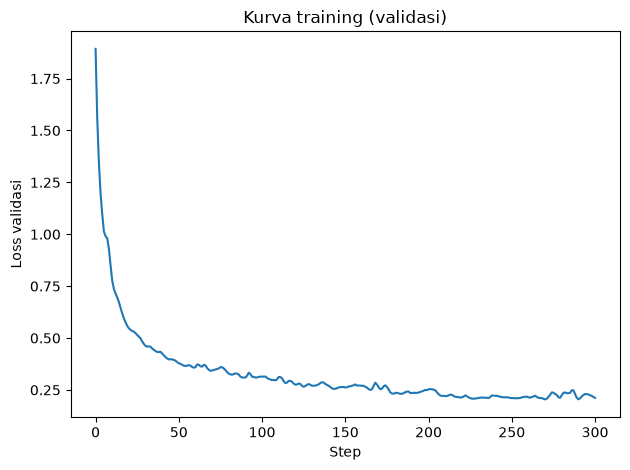

In [34]:
loss, acc_val, acc_test, history = train(
    lambda: make_adam(lr=0.01), steps=300,
    sizes=(12, 64, 32, 10), seed=SEED, data=data, track=True,
)
print(f"\nHasil 1x latih (Adam): loss latih={loss:.4f}, val={acc_val:.4f}, uji={acc_test:.4f}")

plt.figure()
plt.plot(history)
plt.xlabel("Step")
plt.ylabel("Loss validasi")
plt.title("Kurva training (validasi)")
plt.tight_layout()
plt.savefig("kurva_training.png")  # saved to disk even if the figure window is closed
print("Kurva disimpan ke: kurva_training.png")
plt.show()


## 18. Laporan akhir: Tabel Ringkasan Kinerja Utama

Format akademis: Train Loss + Val Loss + Train/Val Acc berdampingan untuk deteksi *overfitting* langsung. Kolom Status diisi otomatis via `fit_status` (gap train-val > 3% atau val_loss >> train_loss = Overfit). Hyperparameter disamakan agar adil: batch=64, epochs=20, lr=1e-3 (Adam/RMSprop), lr=1e-2 (SGD/Momentum), loss=Cross-Entropy.

In [35]:
HYPERPARAMS = {
    "batch_size": 64,
    "epochs": 20,
    "loss": "Cross-Entropy Loss",
    "sizes": (12, 64, 32, 10),
    "init": "he",
    "activation": "relu",
}
OPTIMIZERS = [
    ("Adam", lambda: make_adam(lr=1e-3), "1e-3"),
    ("RMSprop", lambda: make_rmsprop(lr=1e-3), "1e-3"),
    ("Momentum", lambda: make_momentum(lr=1e-2), "1e-2"),
    ("SGD", lambda: make_sgd(lr=1e-2), "1e-2"),
]

summary_rows, curves_bank, models_bank = [], {}, {}
for name, factory, lr_str in OPTIMIZERS:
    tr_loss, va_loss, tr_acc, va_acc, te_acc, curves, model = train_epochs(
        factory, epochs=HYPERPARAMS["epochs"], batch_size=HYPERPARAMS["batch_size"],
        sizes=HYPERPARAMS["sizes"], init=HYPERPARAMS["init"],
        activation=HYPERPARAMS["activation"], seed=SEED, data=data, return_model=True,
    )
    curves_bank[name] = curves
    models_bank[name] = model
    summary_rows.append({
        "Optimizer": name,
        "Train Loss": tr_loss,
        "Val Loss": va_loss,
        "Train Acc (%)": tr_acc * 100,
        "Val Acc (%)": va_acc * 100,
        "Test Acc (%)": te_acc * 100,
        "Status": fit_status(tr_acc, va_acc, tr_loss, va_loss),
    })

summary_df = pd.DataFrame(summary_rows).set_index("Optimizer")
print("1. TABEL RINGKASAN KINERJA UTAMA")
print(summary_df.to_string(float_format="%.4f"))
print("\nHyperparameter Setup:")
print(f"  Batch Size: {HYPERPARAMS['batch_size']}, Epochs: {HYPERPARAMS['epochs']}, "
      f"Loss: {HYPERPARAMS['loss']}")
for name, _, lr_str in OPTIMIZERS:
    print(f"  lr ({name}): {lr_str}")

1. TABEL RINGKASAN KINERJA UTAMA
           Train Loss  Val Loss  Train Acc (%)  Val Acc (%)  Test Acc (%) Status
Optimizer                                                                       
Adam           0.0701    0.0916        97.3285      96.4264       96.2437    Fit
RMSprop        0.0723    0.0930        97.2588      96.3858       96.4467    Fit
Momentum       0.0583    0.0740        97.9115      97.2995       96.8934    Fit
SGD            0.2080    0.2190        92.2551      91.8376       91.6548    Fit

Hyperparameter Setup:
  Batch Size: 64, Epochs: 20, Loss: Cross-Entropy Loss
  lr (Adam): 1e-3
  lr (RMSprop): 1e-3
  lr (Momentum): 1e-2
  lr (SGD): 1e-2


## 19. Laporan Metrik Per Kelas (Classification Report — Adam, data uji)

Precision/Recall/F1 per kelas membuktikan model seimbang / tidak bias. `support` = jumlah sampel uji per kelas. Macro avg = rata-rata tanpa bobot; weighted avg = dibobot support.

In [36]:
best_model = models_bank["Adam"]
yte_true = np.asarray(yte)
yte_pred = predict(best_model, Xte)
class_names = list(_label_encoder.classes_) if _label_encoder is not None else None
print("2. CLASSIFICATION REPORT — Adam (data uji)\n")
print(classification_report(yte_true, yte_pred, target_names=class_names,
                            digits=4, zero_division=0))

2. CLASSIFICATION REPORT — Adam (data uji)

                      precision    recall  f1-score   support

             Anxiety     0.9745    0.9322    0.9529       738
              Autism     0.5000    0.3529    0.4138        17
Bipolar (Depression)     0.9167    0.6600    0.7674        50
     Bipolar (Mania)     0.9887    0.9296    0.9582       753
            Dementia     0.0000    0.0000    0.0000         1
          Depression     1.0000    0.5238    0.6875        21
 Normal/Unclassified     0.9567    0.9904    0.9732      3322
                 OCD     0.0000    0.0000    0.0000         1
                PTSD     1.0000    0.3333    0.5000         6
       Schizophrenia     0.9091    0.6250    0.7407        16

            accuracy                         0.9624      4925
           macro avg     0.7246    0.5347    0.5994      4925
        weighted avg     0.9620    0.9624    0.9609      4925



## 20. Grafik: Confusion Matrix + Learning Curves (Loss & Accuracy vs Epoch)

- Confusion matrix: diagonal = benar; luar diagonal = pola eror (mis. Depression tertukar Bipolar).
- Learning curves: kurva Train vs Validation sejajar = Fit; Val menjauh = Overfit.

Confusion matrix disimpan ke: confusion_matrix_adam.png


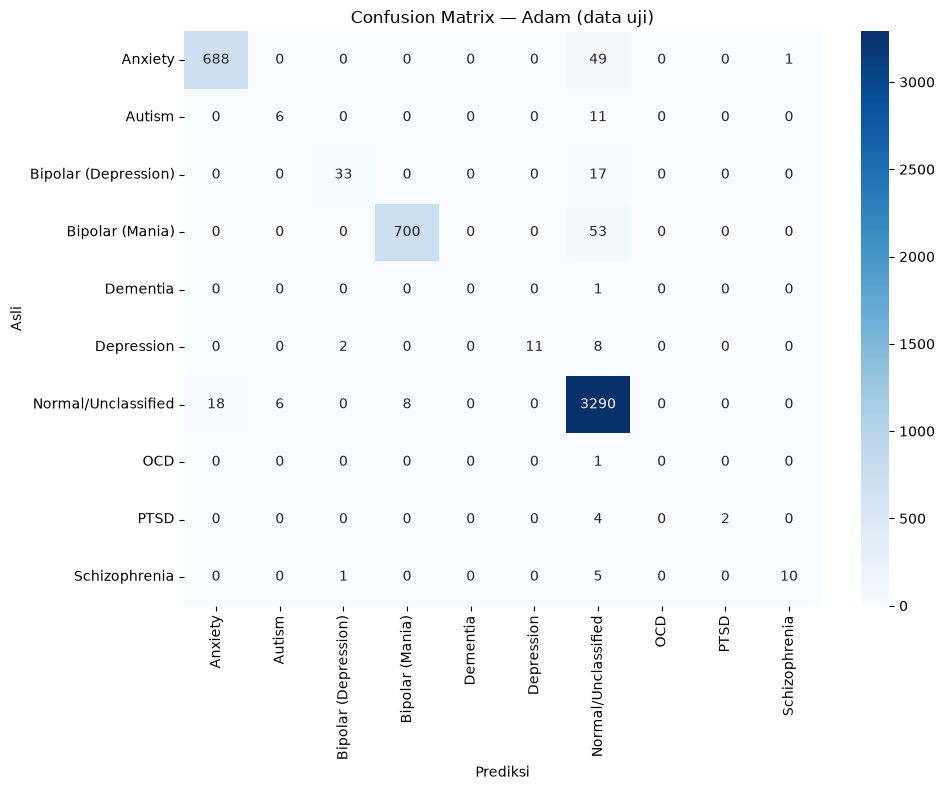

In [37]:
cm = confusion_matrix(yte_true, yte_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Asli")
plt.title("Confusion Matrix — Adam (data uji)")
plt.tight_layout()
plt.savefig("confusion_matrix_adam.png")
print("Confusion matrix disimpan ke: confusion_matrix_adam.png")
plt.show()

Learning curves disimpan ke: learning_curves.png


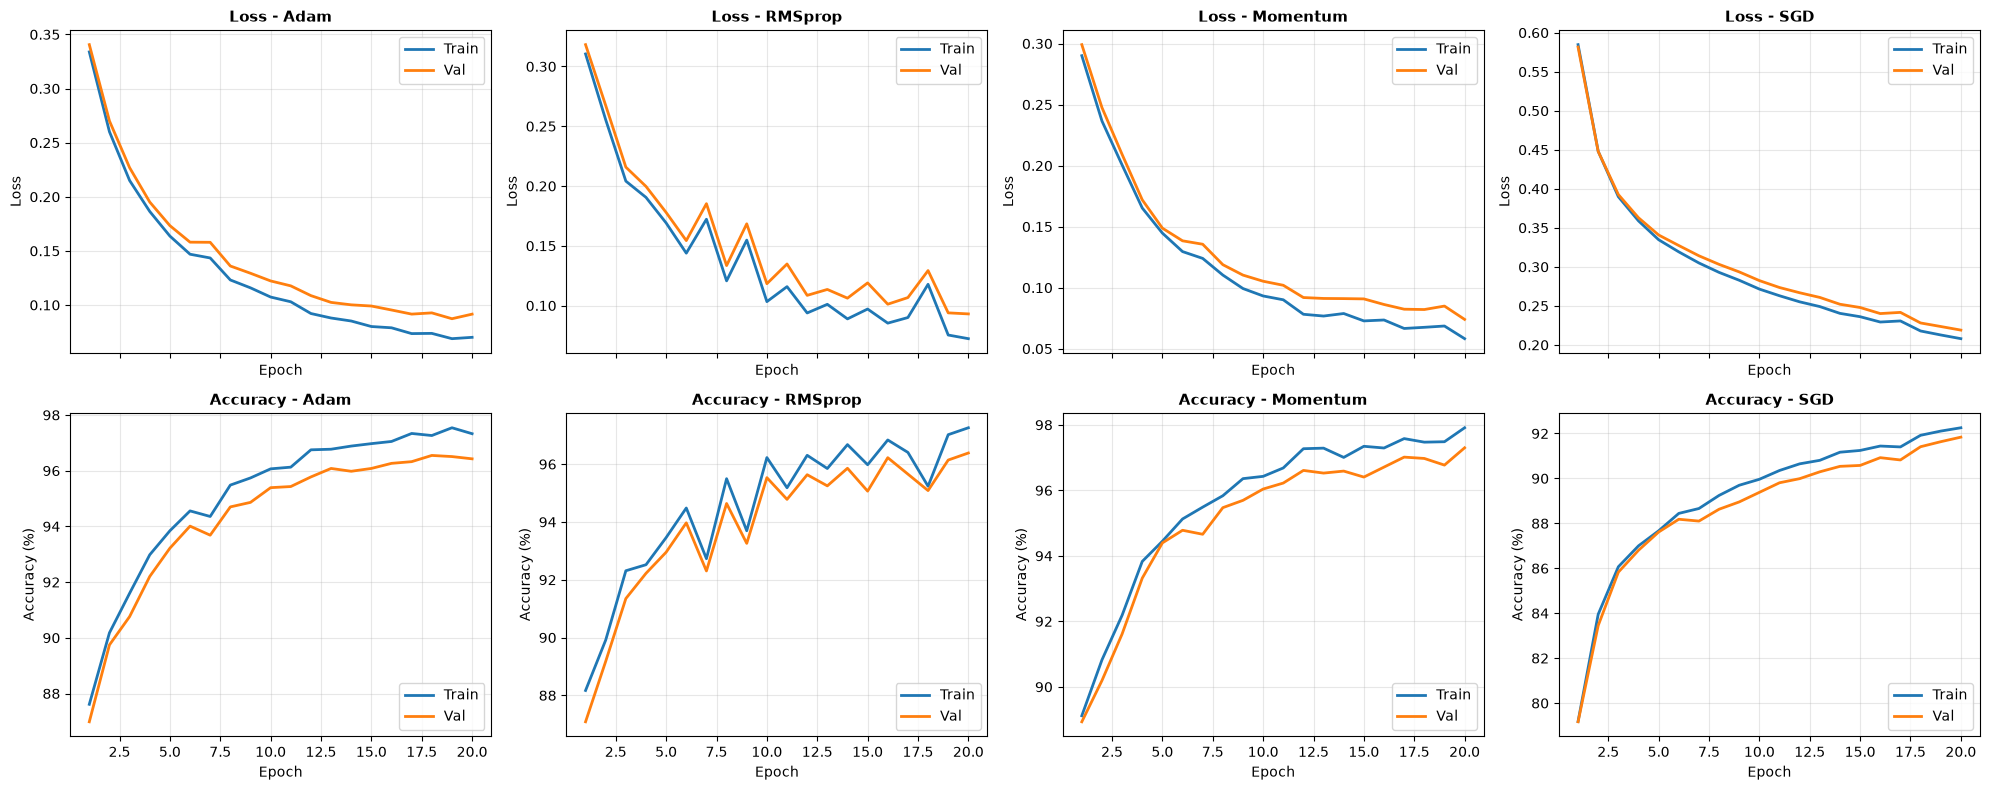

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True)

epochs_axis = range(1, HYPERPARAMS["epochs"] + 1)

for idx, (name, _, _) in enumerate(OPTIMIZERS):
    c = curves_bank[name]
    
    # --- Baris 1: Plot Loss ---
    ax_loss = axes[0, idx]
    ax_loss.plot(epochs_axis, c["train_loss"], label="Train", color="#1f77b4", linewidth=2)
    ax_loss.plot(epochs_axis, c["val_loss"], label="Val", color="#ff7f0e", linewidth=2)
    ax_loss.set_title(f"Loss - {name}", fontsize=11, fontweight="bold")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Loss")
    ax_loss.legend(loc="upper right")
    ax_loss.grid(True, alpha=0.3)
    
    # --- Baris 2: Plot Accuracy ---
    ax_acc = axes[1, idx]
    ax_acc.plot(epochs_axis, np.array(c["train_acc"]) * 100, label="Train", color="#1f77b4", linewidth=2)
    ax_acc.plot(epochs_axis, np.array(c["val_acc"]) * 100, label="Val", color="#ff7f0e", linewidth=2)
    ax_acc.set_title(f"Accuracy - {name}", fontsize=11, fontweight="bold")
    ax_acc.set_xlabel("Epoch")
    ax_acc.set_ylabel("Accuracy (%)")
    ax_acc.legend(loc="lower right")
    ax_acc.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
print("Learning curves disimpan ke: learning_curves.png")
plt.show()